# Bài tập thực hành 1: Trực quan hóa dữ liệu chất lượng rượu vang đỏ
Dữ liệu: `winequality-red.csv` (1599 mẫu, 11 thuộc tính hóa lý + `quality`).

## 1. Chuẩn bị dữ liệu

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

wine = pd.read_csv('winequality-red.csv')
print(wine.shape, '| thiếu:', wine.isna().sum().sum(), '| trùng:', wine.duplicated().sum())
wine.describe().T[['mean','std','min','max']]

(1599, 12) | thiếu: 0 | trùng: 240


,mean,std,min,max
fixed acidity,8.319637,1.741096,4.60000,15.90000
volatile acidity,0.527821,0.179060,0.12000,1.58000
citric acid,0.270976,0.194801,0.00000,1.00000
residual sugar,2.538806,1.409928,0.90000,15.50000
chlorides,0.087467,0.047065,0.01200,0.61100
free sulfur dioxide,15.874922,10.460157,1.00000,72.00000
total sulfur dioxide,46.467792,32.895324,6.00000,289.00000
density,0.996747,0.001887,0.99007,1.00369
pH,3.311113,0.154386,2.74000,4.01000
sulphates,0.658149,0.169507,0.33000,2.00000


## 2. Matplotlib

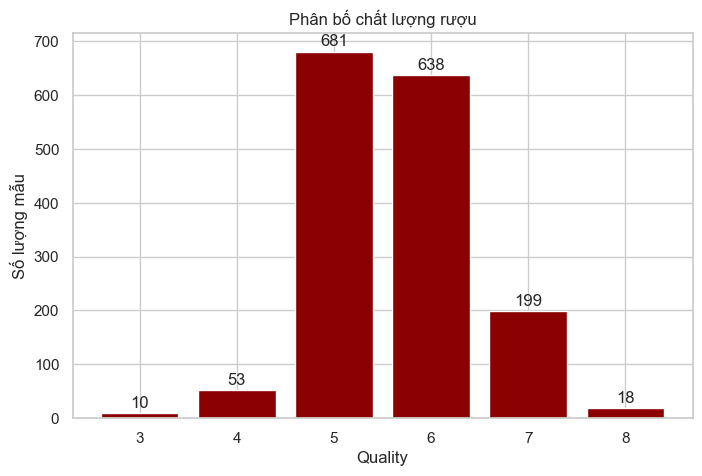

In [2]:
# Phân bố chất lượng rượu (bar chart)
counts = wine['quality'].value_counts().sort_index()
plt.figure(figsize=(8,5))
plt.bar(counts.index, counts.values, color='darkred')
plt.xlabel('Quality'); plt.ylabel('Số lượng mẫu'); plt.title('Phân bố chất lượng rượu')
for x, y in counts.items(): plt.text(x, y+10, y, ha='center')
plt.show()

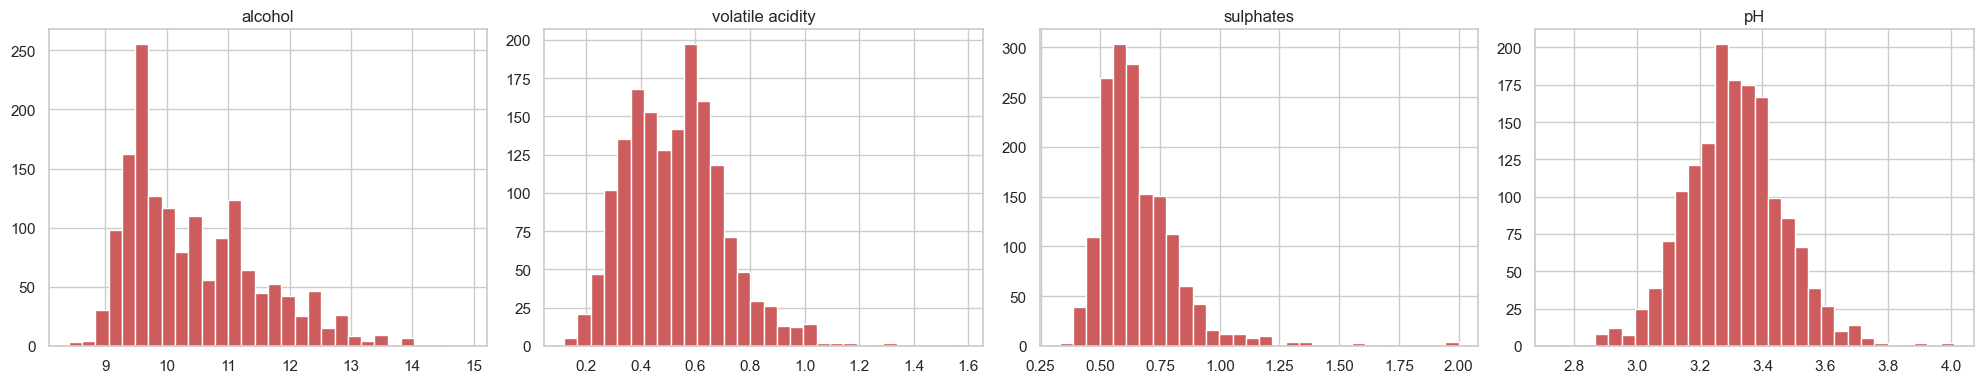

In [3]:
# Histogram của 4 thuộc tính tiêu biểu
cols = ['alcohol','volatile acidity','sulphates','pH']
fig, ax = plt.subplots(1, 4, figsize=(20,4))
for a, c in zip(ax, cols):
    a.hist(wine[c], bins=30, color='indianred', edgecolor='white'); a.set_title(c)
plt.tight_layout(); plt.show()

**Nhận xét:** phần lớn rượu có chất lượng 5–6 (dữ liệu mất cân bằng); `alcohol`, `sulphates` lệch phải, `pH` gần phân phối chuẩn.

## 3. Seaborn

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16144\509053193.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=wine, x='quality', y=c, ax=a, palette='Reds')
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16144\509053193.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=wine, x='quality', y=c, ax=a, palette='Reds')
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16144\509053193.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=wine, x='quality', y=c, ax=a, palette='Reds')


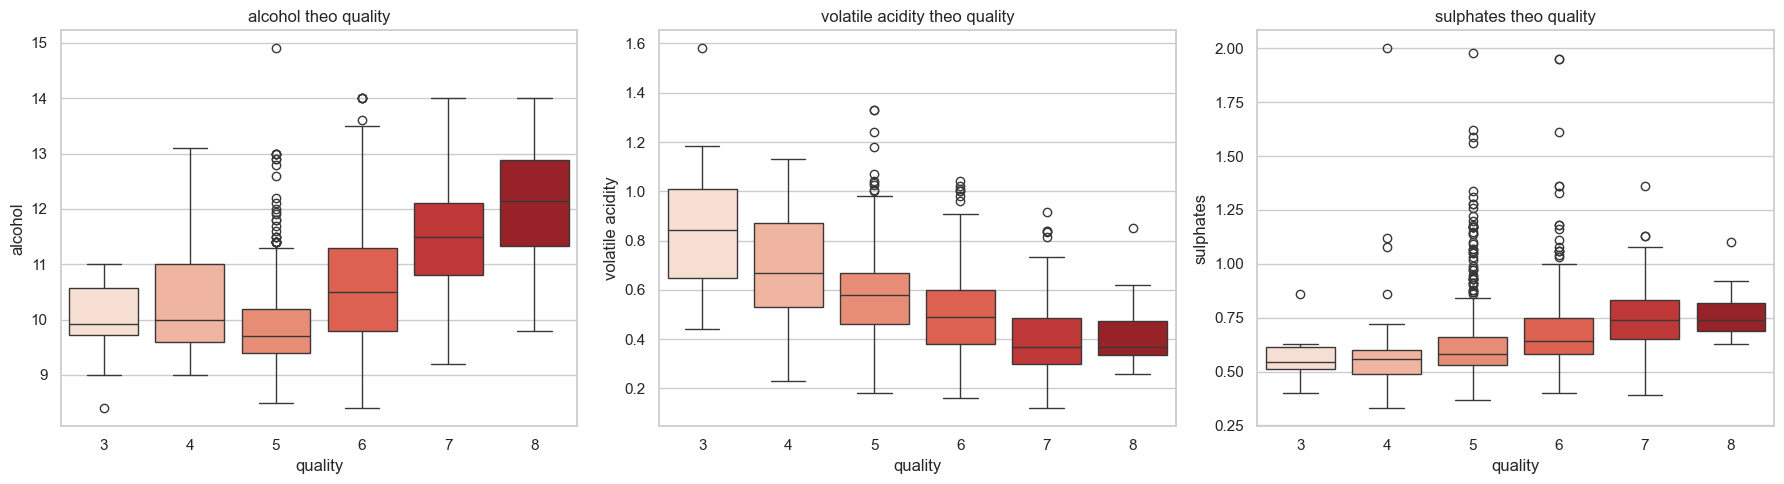

In [4]:
# Boxplot: các thuộc tính liên quan mạnh đến quality
fig, ax = plt.subplots(1, 3, figsize=(18,5))
for a, c in zip(ax, ['alcohol','volatile acidity','sulphates']):
    sns.boxplot(data=wine, x='quality', y=c, ax=a, palette='Reds')
    a.set_title(f'{c} theo quality')
plt.tight_layout(); plt.show()

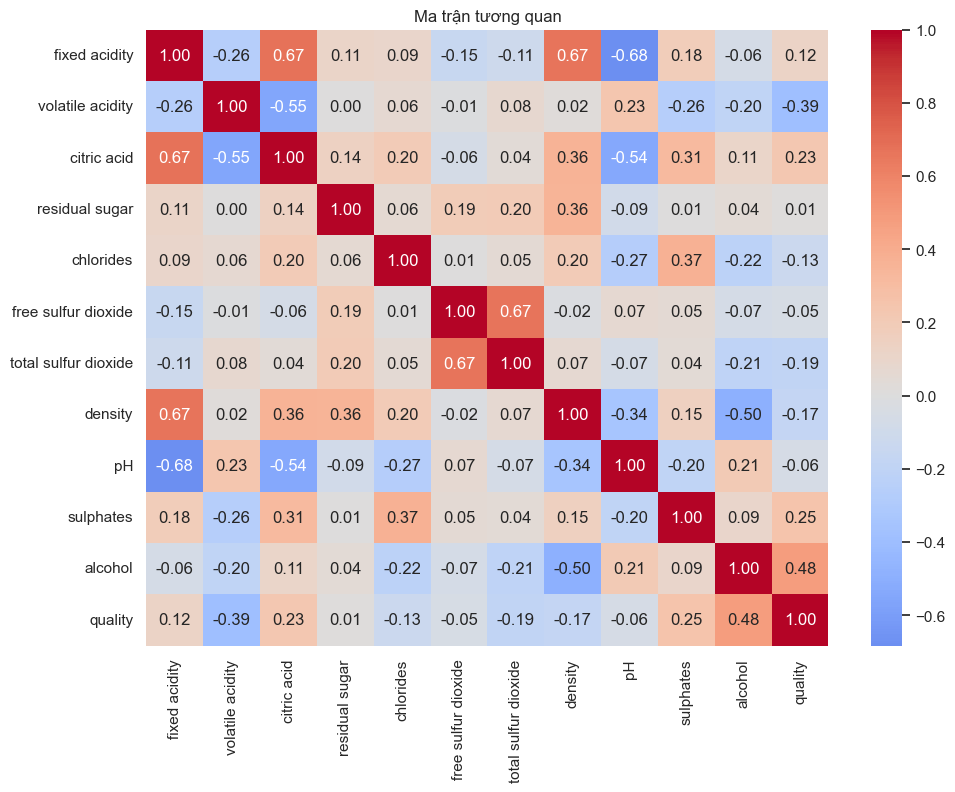

volatile acidity       -0.390558
total sulfur dioxide   -0.185100
density                -0.174919
chlorides              -0.128907
pH                     -0.057731
free sulfur dioxide    -0.050656
residual sugar          0.013732
fixed acidity           0.124052
citric acid             0.226373
sulphates               0.251397
alcohol                 0.476166
Name: quality, dtype: float64

In [5]:
# Heatmap tương quan
plt.figure(figsize=(11,8))
sns.heatmap(wine.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Ma trận tương quan'); plt.show()
wine.corr()['quality'].drop('quality').sort_values()

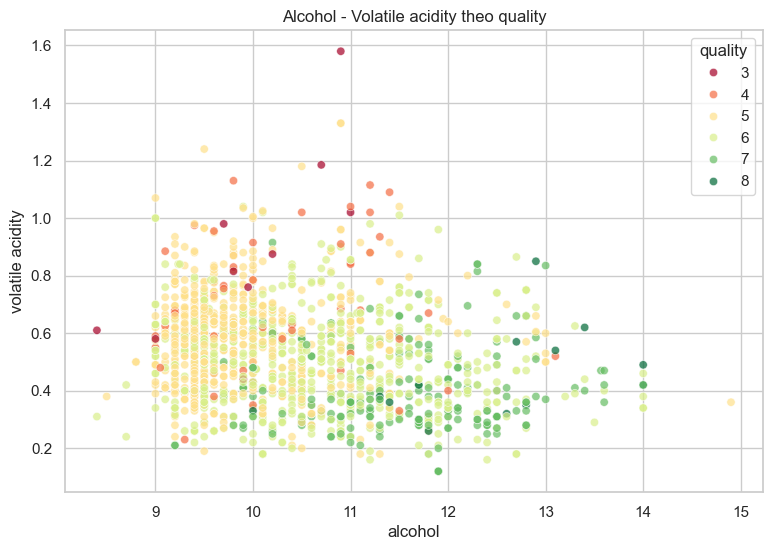

In [6]:
# Scatter: alcohol vs volatile acidity theo quality
plt.figure(figsize=(9,6))
sns.scatterplot(data=wine, x='alcohol', y='volatile acidity', hue='quality', palette='RdYlGn', alpha=.7)
plt.title('Alcohol - Volatile acidity theo quality'); plt.show()

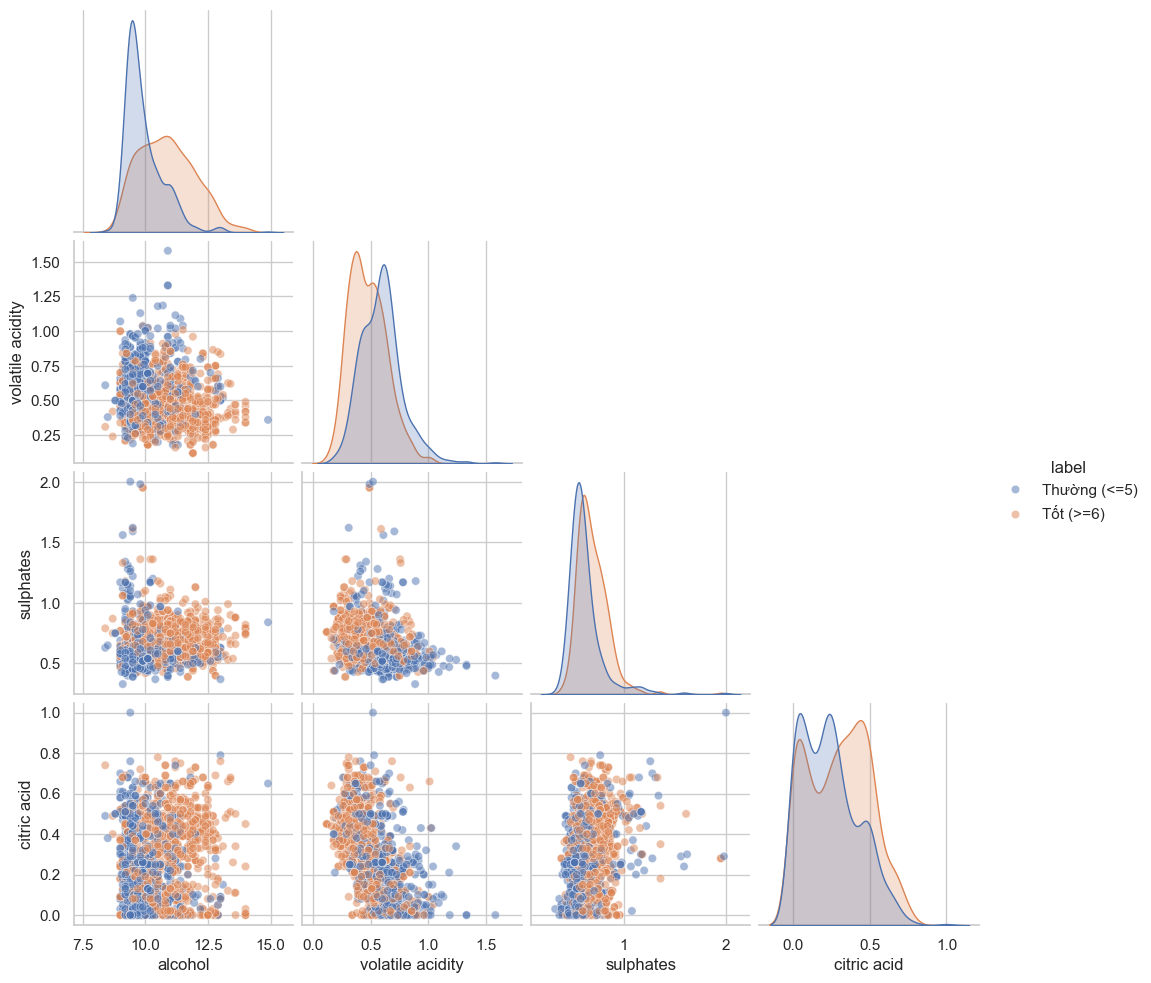

In [7]:
# Nhóm chất lượng: thấp (<=5) / cao (>=6) và pairplot
wine['label'] = (wine['quality'] >= 6).map({True:'Tốt (>=6)', False:'Thường (<=5)'})
sns.pairplot(wine, vars=['alcohol','volatile acidity','sulphates','citric acid'], hue='label', corner=True, plot_kws={'alpha':.5})
plt.savefig('wine_pairplot.png', dpi=150, bbox_inches='tight')   # xuất PNG dùng cho báo cáo
plt.show()

## 4. Kết luận
- `alcohol` (r≈0.48), `sulphates`, `citric acid` tương quan **dương** với chất lượng; `volatile acidity` (r≈-0.39) tương quan **âm**.
- Rượu chất lượng cao thường có độ cồn cao hơn và độ axit bay hơi thấp hơn.
- Dữ liệu tập trung ở quality 5–6 nên cần chú ý mất cân bằng lớp khi xây mô hình phân loại.